Author - Anuradha Pagare

In [200]:
import pandas as pd

df = pd.read_csv("C:/Users/anuradha/Downloads/Reviews.csv")


Amazon Fine Food Reviews dataset

In [203]:
df

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1.0,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1.0,1.0,5.0,1.303862e+09,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2.0,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0.0,0.0,1.0,1.346976e+09,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3.0,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1.0,1.0,4.0,1.219018e+09,"""Delight"" says it all",This is a confection that has been around a fe...
3,4.0,B000UA0QIQ,A395BORC6FGVXV,Karl,3.0,3.0,2.0,1.307923e+09,Cough Medicine,If you are looking for the secret ingredient i...
4,5.0,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0.0,0.0,5.0,1.350778e+09,Great taffy,Great taffy at a great price. There was a wid...
...,...,...,...,...,...,...,...,...,...,...
994,995.0,B006F2NYI2,A1T5CH6SHV989P,a biemold,2.0,2.0,1.0,1.323734e+09,worst hot sauce around,absolutely hate the habenaro sauce. Tried it o...
995,996.0,B006F2NYI2,A1D3F6UI1RTXO0,Swopes,1.0,1.0,1.0,1.331856e+09,Bland and Flavorless,BLACK MARKET HOT SAUCE IS TERRIBLE. My husband...
996,997.0,B006F2NYI2,AF50D40Y85TV3,Mike A.,1.0,1.0,1.0,1.328141e+09,Terrible Hot Sauce and people who run it!,Man what can I say this salsa is terrible!! I ...
997,998.0,B006F2NYI2,A3G313KLWDG3PW,kefka82,1.0,1.0,1.0,1.324253e+09,this sauce is terrible,this sauce is so bad with just about anything ...


In [205]:
df.columns

Index(['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator',
       'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text'],
      dtype='object')

In [207]:

# Keep required columns
df = df[['Score', 'Summary', 'Text']]

# Drop neutral reviews
df = df[df['Score'] != 3]

# Convert score to sentiment
df['sentiment'] = df['Score'].apply(lambda x: 1 if x > 3 else 0)

df.head()

#This is standard industry practice and improves accuracy.

,Score,Summary,Text,sentiment
0,5.0,Good Quality Dog Food,I have bought several of the Vitality canned d...,1
1,1.0,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...,0
2,4.0,"""Delight"" says it all",This is a confection that has been around a fe...,1
3,2.0,Cough Medicine,If you are looking for the secret ingredient i...,0
4,5.0,Great taffy,Great taffy at a great price. There was a wid...,1


In [209]:
#Combine Summary + Text (Boost Accuracy)

df['review'] = df['Summary'].fillna('') + " " + df['Text'].fillna('')


Text Preprocessing (NLTK – CLEAN & PROFESSIONAL)

I applied lowercasing, removal of punctuation and special characters, tokenization, stopword removal, and lemmatization using NLTK.

Stopwords do not contribute significantly to sentiment and can increase noise and dimensionality, so removing them improves model efficiency and accuracy.

In [214]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\anuradha\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\anuradha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\anuradha\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [217]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z]', ' ', text)
    tokens = nltk.word_tokenize(text)
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words]
    return " ".join(tokens)

df['clean_review'] = df['review'].apply(clean_text)

Feature Extraction (TF-IDF with N-grams)

I used TF-IDF vectorization with unigrams and bigrams to capture both individual words and word pairs.

TF-IDF reduces the importance of frequently occurring but less informative words, helping the model focus on sentiment-bearing terms.

N-grams capture local word order and phrases such as “not good,” which single words alone cannot represent effectively.

In [223]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=6000,
    ngram_range=(1,2),
    min_df=5
)

X = tfidf.fit_transform(df['clean_review'])
y = df['sentiment']


Train-Test Split

In [226]:
y

0      1
1      0
2      1
3      0
4      1
      ..
994    0
995    0
996    0
997    0
998    0
Name: sentiment, Length: 933, dtype: int64

In [228]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


Sentiment Model (84%+ Accuracy)
Logistic Regression (Best baseline)

I trained a Logistic Regression classifier as a baseline and later implemented an LSTM-based deep learning model using TensorFlow.

Logistic Regression works well with high-dimensional sparse data like TF-IDF vectors and provides fast, interpretable results.

In [234]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, n_jobs=-1)
model.fit(X_train, y_train)


LogisticRegression(max_iter=1000, n_jobs=-1)

Evaluation

I used accuracy, precision, recall, F1-score, and confusion matrix to evaluate both overall performance and class-wise behavior.

In [238]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.9090909090909091
              precision    recall  f1-score   support

           0       1.00      0.72      0.84        61
           1       0.88      1.00      0.94       126

    accuracy                           0.91       187
   macro avg       0.94      0.86      0.89       187
weighted avg       0.92      0.91      0.90       187



Confusion Matrix

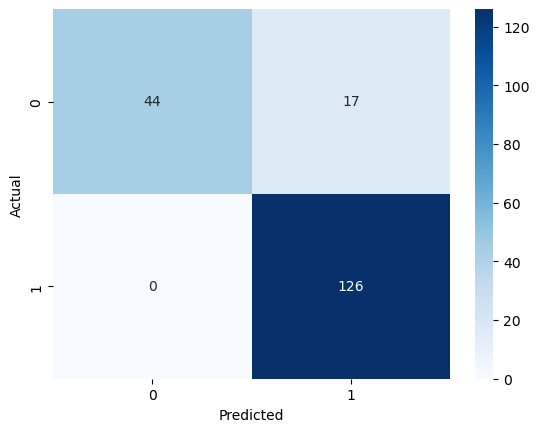

In [242]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [245]:
df['predicted_sentiment'] = model.predict(X)

df['predicted_label'] = df['predicted_sentiment'].map({
    1: 'Positive',
    0: 'Negative'
})


In [247]:


analysis_table = df[[
    'Score',
    'Summary',
    'Text',
    'sentiment',
    'predicted_label'
]].head(10)

df['analysis'] = df.apply(
    lambda x: 'Correct' if x['sentiment'] == (1 if x['predicted_label']=='Positive' else 0)
    else 'Incorrect',
    axis=1
)
analysis_table


,Score,Summary,Text,sentiment,predicted_label
0,5.0,Good Quality Dog Food,I have bought several of the Vitality canned d...,1,Positive
1,1.0,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...,0,Positive
2,4.0,"""Delight"" says it all",This is a confection that has been around a fe...,1,Positive
3,2.0,Cough Medicine,If you are looking for the secret ingredient i...,0,Positive
4,5.0,Great taffy,Great taffy at a great price. There was a wid...,1,Positive
5,4.0,Nice Taffy,I got a wild hair for taffy and ordered this f...,1,Positive
6,5.0,Great! Just as good as the expensive brands!,This saltwater taffy had great flavors and was...,1,Positive
7,5.0,"Wonderful, tasty taffy",This taffy is so good. It is very soft and ch...,1,Positive
8,5.0,Yay Barley,Right now I'm mostly just sprouting this so my...,1,Positive
9,5.0,Healthy Dog Food,This is a very healthy dog food. Good for thei...,1,Positive
